# Early Sepsis Prediction: GA + ANFIS + PSO (v2)
**Soft Computing AAT (MMCE30C3)** | Lohith S, Manjunath H

What is new in v2:
1. All 20,336 patients of PhysioNet 2019 Set A, **split by patient** (no leakage), tested on the **natural ~2% sepsis rate**
2. ~37 candidate features: vitals, labs, **6-hour trends**, lab-ordering counts
3. **GA** picks 3 to 6 features using a wrapper fitness (AUROC)
4. **ANFIS** rules come from **k-means**; consequents by least squares (Jang's hybrid ANFIS)
5. **PSO** tunes the fuzzy curves, starts from the k-means solution, decaying inertia
6. Alert **threshold chosen on validation data** (target sensitivity), baselines (LR, Random Forest) and explanations

Run top to bottom (Runtime > Run all). Set `QUICK_MODE=True` first for a fast test (3000 patients).

In [14]:
import os, re, glob, time, warnings, requests, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from scipy.stats import rankdata
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, confusion_matrix
warnings.filterwarnings('ignore')

# ---------------- SETTINGS ----------------
QUICK_MODE   = False          # True = 3000 patients, quick test
SEED         = 42
TARGET_SENS  = 0.80           # alert threshold is chosen so that ~80% of sepsis rows are caught (on validation data)
K_MIN, K_MAX = 3, 6           # GA may select between 3 and 6 features
N_RULES      = 8              # fuzzy rules (k-means clusters)
GA_POP, GA_GEN = 30, 25
PSO_PARTICLES, PSO_ITERS = 40, 60
N_PATIENTS   = 3000 if QUICK_MODE else None
# -------------------------------------------
rng = np.random.default_rng(SEED); np.random.seed(SEED)
os.makedirs('figs', exist_ok=True)
print('Setup done')

Setup done


## 1. Download data (PhysioNet 2019, Training Set A)
Takes about 3 to 6 minutes the first time (20,336 small files, downloaded in parallel).

In [15]:
BASE = 'https://physionet.org/files/challenge-2019/1.0.0/training/training_setA/'
os.makedirs('data/setA', exist_ok=True)
if len(glob.glob('data/setA/*.psv')) < 20000 and not QUICK_MODE or len(glob.glob('data/setA/*.psv')) < 3000:
    html = requests.get(BASE, timeout=60).text
    names = sorted(set(re.findall(r'(p\d{6}\.psv)', html)))
    print('files listed:', len(names))
    if QUICK_MODE: names = names[:N_PATIENTS]
    sess = requests.Session()
    def grab(n):
        p = f'data/setA/{n}'
        if os.path.exists(p): return
        for _ in range(4):
            try:
                r = sess.get(BASE+n, timeout=60)
                if r.status_code == 200:
                    open(p,'wb').write(r.content); return
            except Exception: time.sleep(1)
    t=time.time()
    with ThreadPoolExecutor(16) as ex: list(ex.map(grab, names))
    print('downloaded in %.0fs' % (time.time()-t))
print('patient files on disk:', len(glob.glob('data/setA/*.psv')))

patient files on disk: 20336


## 2. Load data

In [16]:
files = sorted(glob.glob('data/setA/*.psv'))
if N_PATIENTS: files = files[:N_PATIENTS]
dfs = []
for i, f in enumerate(files):
    d = pd.read_csv(f, sep='|'); d['pid'] = i; dfs.append(d)
df = pd.concat(dfs, ignore_index=True); del dfs
print('patients:', df.pid.nunique(), '| hourly records:', len(df))
print('sepsis records: %d (%.2f%%)' % (df.SepsisLabel.sum(), 100*df.SepsisLabel.mean()))
print('sepsis patients: %d' % df.groupby('pid').SepsisLabel.max().sum())

patients: 20336 | hourly records: 790215
sepsis records: 17136 (2.17%)
sepsis patients: 1790


## 3. Patient-level split + feature engineering
Split is by **patient** (60% train / 20% validation / 20% test). Imputation medians and scaling use training data only.

In [17]:
pid_all = df.groupby('pid').SepsisLabel.max()
tr_p, tmp_p = train_test_split(pid_all.index.values, test_size=0.4, random_state=SEED, stratify=pid_all.values)
va_p, te_p  = train_test_split(tmp_p, test_size=0.5, random_state=SEED, stratify=pid_all.loc[tmp_p].values)
# inside training patients: 'fit' (learn parameters) and 'sel' (judge GA / PSO candidates)
fit_p, sel_p = train_test_split(tr_p, test_size=0.3, random_state=SEED, stratify=pid_all.loc[tr_p].values)

VIT = ['HR','O2Sat','Temp','SBP','MAP','DBP','Resp']
LAB = ['WBC','Lactate','Creatinine','Platelets','BUN']
base = VIT + LAB
g = df['pid']
ff = df.groupby('pid')[base].ffill()                     # last known value of the patient
F = pd.DataFrame(index=df.index)
F[base] = ff
F['ShockIndex'] = ff['HR'] / ff['SBP']
F['Age'] = df['Age']; F['ICULOS'] = df['ICULOS']
for c in LAB:                                            # how many times this lab was measured so far
    F[c+'_count'] = df[c].notna().groupby(g).cumsum().astype(float)
gb = ff.groupby(g)
for c in ['HR','O2Sat','Temp','SBP','MAP','Resp']:
    F[c+'_d6'] = ff[c] - gb[c].shift(6)                  # change over last 6 hours
    F[c+'_m6'] = gb[c].rolling(6, min_periods=1).mean().reset_index(level=0, drop=True)
for c in ['HR','Temp','SBP','Resp','MAP']:
    F[c+'_s6'] = gb[c].rolling(6, min_periods=2).std().reset_index(level=0, drop=True)
F = F.replace([np.inf,-np.inf], np.nan)
trend_cols = [c for c in F.columns if c.endswith('_d6') or c.endswith('_s6')]
F[trend_cols] = F[trend_cols].fillna(0)

pid = df['pid'].values; y = df['SepsisLabel'].values.astype(int)
tr_mask = np.isin(pid, tr_p)
F = F.fillna(F[tr_mask].median())                        # medians from training patients only
mu, sd = F[tr_mask].mean(), F[tr_mask].std().replace(0,1)
X = ((F-mu)/sd).clip(-5,5).values.astype(np.float32)
FEATS = list(F.columns)
print('candidate features:', len(FEATS))

idx_of = lambda P: np.where(np.isin(pid, P))[0]
va_idx, te_idx = idx_of(va_p), idx_of(te_p)              # natural distribution (~2% sepsis)
def make_subset(P, n_pos, n_neg):
    m = np.isin(pid, P)
    pos = np.where(m&(y==1))[0]; neg = np.where(m&(y==0))[0]
    pos = rng.choice(pos, min(n_pos,len(pos)), replace=False)
    neg = rng.choice(neg, min(n_neg,len(neg)), replace=False)
    i = np.concatenate([pos,neg]); rng.shuffle(i); return i
fit_idx = make_subset(fit_p, 4000, 8000)
sel_idx = make_subset(sel_p, 2500, 5000)
print('train-fit rows %d | train-select rows %d | validation rows %d | test rows %d' % (len(fit_idx),len(sel_idx),len(va_idx),len(te_idx)))
print('test sepsis rate: %.2f%%' % (100*y[te_idx].mean()))

candidate features: 37
train-fit rows 12000 | train-select rows 7500 | validation rows 157812 | test rows 159397
test sepsis rate: 2.14%


## 4. Genetic Algorithm: feature selection
Chromosome = 0/1 per feature. Fitness = AUROC of a quick classifier on the *select* patients minus a small penalty per feature. Between 3 and 6 features allowed.

In [18]:
def auc_fast(yy, s):
    yy = np.asarray(yy); r = rankdata(s); n1 = yy.sum(); n0 = len(yy)-n1
    return (r[yy==1].sum() - n1*(n1+1)/2) / (n1*n0)

nF = X.shape[1]
Xa, ya, Xb, yb = X[fit_idx], y[fit_idx], X[sel_idx], y[sel_idx]
cache = {}
def ga_fitness(m):
    key = m.tobytes()
    if key not in cache:
        cols = np.flatnonzero(m)
        lr = LogisticRegression(max_iter=100, class_weight='balanced').fit(Xa[:,cols], ya)
        a = auc_fast(yb, lr.decision_function(Xb[:,cols]))
        cache[key] = (a - 0.004*len(cols), a)
    return cache[key]
def repair(m):
    on = np.flatnonzero(m)
    if len(on) > K_MAX: m[rng.choice(on, len(on)-K_MAX, replace=False)] = False
    on = np.flatnonzero(m)
    if len(on) < K_MIN: m[rng.choice(np.flatnonzero(~m), K_MIN-len(on), replace=False)] = True
    return m
def rand_chrom():
    m = np.zeros(nF, bool); m[rng.choice(nF, rng.integers(K_MIN,K_MAX+1), replace=False)] = True; return m

t0 = time.time()
pop = [rand_chrom() for _ in range(GA_POP)]
ga_best_hist, ga_mean_hist = [], []
for gen in range(GA_GEN):
    fit = np.array([ga_fitness(m)[0] for m in pop])
    ga_best_hist.append(fit.max()); ga_mean_hist.append(fit.mean())
    order = np.argsort(-fit)
    new = [pop[order[0]].copy(), pop[order[1]].copy()]                  # elitism
    while len(new) < GA_POP:
        pick = lambda: pop[max(rng.choice(GA_POP,3,replace=False), key=lambda i: fit[i])]   # tournament
        p1, p2 = pick(), pick()
        child = np.where(rng.random(nF)<0.5, p1, p2) if rng.random()<0.8 else p1.copy()      # uniform crossover
        child = child ^ (rng.random(nF) < 0.04)                                              # mutation
        new.append(repair(child))
    pop = new
    if (gen+1)%5==0: print(f'GA generation {gen+1}/{GA_GEN} | best fitness {fit.max():.4f}')
best = pop[0]; sel_cols = np.flatnonzero(best); sel_names = [FEATS[i] for i in sel_cols]
ga_time = time.time()-t0
lr_all = LogisticRegression(max_iter=200, class_weight='balanced').fit(Xa, ya)
print('\nGA time: %.1fs' % ga_time)
print('Selected features (%d): %s' % (len(sel_names), sel_names))
print('Quick-LR AUROC on select patients | GA subset: %.4f | all %d features: %.4f' % (ga_fitness(best)[1], nF, auc_fast(yb, lr_all.decision_function(Xb))))

GA generation 5/25 | best fitness 0.6889
GA generation 10/25 | best fitness 0.6973
GA generation 15/25 | best fitness 0.6999
GA generation 20/25 | best fitness 0.7013
GA generation 25/25 | best fitness 0.7013

GA time: 14.6s
Selected features (5): ['HR', 'BUN', 'ICULOS', 'Resp_m6', 'Temp_s6']
Quick-LR AUROC on select patients | GA subset: 0.7213 | all 37 features: 0.7287


## 5. ANFIS + PSO
- **Rules:** k-means finds natural patient groups; each group becomes one fuzzy rule with Gaussian curves per feature.
- **Consequents** (the linear formula of each rule) are solved by least squares inside the fitness function (Jang's hybrid ANFIS).
- **PSO** searches the fuzzy curve centres and widths. Particle 1 starts from the k-means solution, others near it or random. Inertia decays 0.9 to 0.4.

In [19]:
R, K = N_RULES, len(sel_cols)
Xs = X[:, sel_cols].astype(np.float64)
Xf, yf, Xv, yv = Xs[fit_idx], y[fit_idx].astype(float), Xs[sel_idx], y[sel_idx].astype(float)
def cw(yy): p = yy.mean(); return np.where(yy==1, 0.5/p, 0.5/(1-p))     # class-balanced weights
swf, swv = cw(yf), cw(yv)

km = KMeans(R, n_init=5, random_state=SEED).fit(Xf)
C0 = km.cluster_centers_
S0 = np.stack([Xf[km.labels_==r].std(0) if (km.labels_==r).sum()>5 else np.ones(K) for r in range(R)]).clip(0.3, 2.5)
v0 = np.concatenate([C0.ravel(), np.log(S0).ravel()])
lo = np.concatenate([np.full(R*K,-5.0), np.full(R*K,np.log(0.15))])
hi = np.concatenate([np.full(R*K, 5.0), np.full(R*K,np.log(4.0))])

def decode(v): return v[:R*K].reshape(R,K), np.exp(v[R*K:]).reshape(R,K)
def phi(Xm, C, S):
    d = (Xm[:,None,:]-C[None])/S[None]
    lw = -0.5*(d*d).sum(2); lw -= lw.max(1, keepdims=True)
    w = np.exp(lw); w /= (w.sum(1, keepdims=True)+1e-12)                 # normalised rule strengths
    Xa_ = np.concatenate([np.ones((len(Xm),1)), Xm], 1)
    return w, (w[:,:,None]*Xa_[:,None,:]).reshape(len(Xm), -1)
def lse(P, yy, sw, lam=1.0):
    A = P.T @ (P*sw[:,None]); A[np.diag_indices_from(A)] += lam
    return np.linalg.solve(A, P.T @ (sw*yy))
def fitness(v):
    C,S = decode(v); _,Pf = phi(Xf,C,S); th = lse(Pf,yf,swf); _,Pv = phi(Xv,C,S); pv = Pv@th
    return (1-auc_fast(yv,pv)) + 0.1*np.average((pv-yv)**2, weights=swv)

t0 = time.time()
D = len(v0); vmax = 0.2*(hi-lo)
X_p = np.vstack([v0] + [np.clip(v0 + rng.normal(0,1,D)*np.r_[np.full(R*K,0.3),np.full(R*K,0.2)], lo, hi) for _ in range(PSO_PARTICLES//2)]
                + [rng.uniform(lo,hi,D) for _ in range(PSO_PARTICLES-1-PSO_PARTICLES//2)])
V_p = rng.uniform(-1,1,(PSO_PARTICLES,D))*vmax*0.1
pbest = X_p.copy(); pfit = np.array([fitness(p) for p in X_p])
g_i = pfit.argmin(); gbest, gfit = pbest[g_i].copy(), pfit[g_i]
init_fit = fitness(v0); pso_hist = [gfit]
for it in range(PSO_ITERS):
    w_in = 0.9 - 0.5*it/(PSO_ITERS-1)
    r1, r2 = rng.random((PSO_PARTICLES,D)), rng.random((PSO_PARTICLES,D))
    V_p = np.clip(w_in*V_p + 1.5*r1*(pbest-X_p) + 1.5*r2*(gbest-X_p), -vmax, vmax)
    X_p = np.clip(X_p+V_p, lo, hi)
    for i in range(PSO_PARTICLES):
        f = fitness(X_p[i])
        if f < pfit[i]:
            pfit[i], pbest[i] = f, X_p[i].copy()
            if f < gfit: gfit, gbest = f, X_p[i].copy()
    pso_hist.append(gfit)
    if (it+1)%10==0: print(f'PSO iteration {it+1}/{PSO_ITERS} | best loss {gfit:.4f}  (k-means start: {init_fit:.4f})')
pso_time = time.time()-t0
print('PSO time: %.1fs' % pso_time)

# final consequents on fit+select rows, using the best premise parameters
u_idx = np.concatenate([fit_idx, sel_idx]); Xu, yu = Xs[u_idx], y[u_idx].astype(float)
def train_theta(v):
    C,S = decode(v); _,P = phi(Xu,C,S); return lse(P, yu, cw(yu))
def anfis_score(v, th, rows, chunk=40000):
    C,S = decode(v); out = []
    for s in range(0, len(rows), chunk):
        _,P = phi(Xs[rows[s:s+chunk]], C, S); out.append(P@th)
    return np.concatenate(out)
th0, th1 = train_theta(v0), train_theta(gbest)
auc_v0 = auc_fast(y[va_idx], anfis_score(v0, th0, va_idx))
auc_v1 = auc_fast(y[va_idx], anfis_score(gbest, th1, va_idx))
print('\nValidation AUROC (natural rate) | k-means rules only: %.4f | after PSO: %.4f' % (auc_v0, auc_v1))

PSO iteration 10/60 | best loss 0.2583  (k-means start: 0.2848)
PSO iteration 20/60 | best loss 0.2555  (k-means start: 0.2848)
PSO iteration 30/60 | best loss 0.2507  (k-means start: 0.2848)
PSO iteration 40/60 | best loss 0.2490  (k-means start: 0.2848)
PSO iteration 50/60 | best loss 0.2457  (k-means start: 0.2848)
PSO iteration 60/60 | best loss 0.2435  (k-means start: 0.2848)
PSO time: 98.1s

Validation AUROC (natural rate) | k-means rules only: 0.7164 | after PSO: 0.7283


## 6. Calibration, threshold and test results
The alert threshold is chosen on **validation** data so that sensitivity is about the target. Test data is used only once, at the end.

In [20]:
s_va = anfis_score(gbest, th1, va_idx); s_te = anfis_score(gbest, th1, te_idx)
platt = LogisticRegression(C=1e6).fit(s_va.reshape(-1,1), y[va_idx])
p_va = platt.predict_proba(s_va.reshape(-1,1))[:,1]; p_te = platt.predict_proba(s_te.reshape(-1,1))[:,1]

def pick_thr(yy, s, target=TARGET_SENS):
    fpr, tpr, thr = roc_curve(yy, s); return thr[np.argmax(tpr >= target)]
def evaluate(name, yy, s, thr, pids):
    pred = (s >= thr).astype(int); tn,fp,fn,tp = confusion_matrix(yy,pred).ravel()
    pa = pd.Series(pred).groupby(pids).max(); pl = pd.Series(yy).groupby(pids).max()
    prec = tp/max(tp+fp,1); sens = tp/max(tp+fn,1)
    return dict(Model=name, AUROC=auc_fast(yy,s), AUPRC=average_precision_score(yy,s), Sensitivity=sens,
                Specificity=tn/(tn+fp), Precision=prec, F1=2*prec*sens/max(prec+sens,1e-9), Accuracy=(tp+tn)/len(yy),
                FalseAlarms_per_TrueAlert=fp/max(tp,1), SepsisPatients_alerted=pa[pl==1].mean(),
                NonSepsisPatients_alerted=pa[pl==0].mean()), (tn,fp,fn,tp)

thr_anfis = pick_thr(y[va_idx], p_va)
res_anfis, cm = evaluate('GA+ANFIS+PSO (ours)', y[te_idx], p_te, thr_anfis, pid[te_idx])
print('Alert threshold (chosen on validation, target sensitivity %.0f%%): %.4f' % (100*TARGET_SENS, thr_anfis))
print('Confusion matrix on TEST (natural rate): TN=%d FP=%d FN=%d TP=%d' % cm)
speed = time.time(); _ = anfis_score(gbest, th1, te_idx[:20000]); per_rec_us = (time.time()-speed)/20000*1e6
print('Prediction time per record: %.2f microseconds' % per_rec_us)
pd.Series(res_anfis)

Alert threshold (chosen on validation, target sensitivity 80%): 0.0133
Confusion matrix on TEST (natural rate): TN=71461 FP=84522 FN=556 TP=2858
Prediction time per record: 1.48 microseconds


,0
Model,GA+ANFIS+PSO (ours)
AUROC,0.754743
AUPRC,0.086026
Sensitivity,0.837141
Specificity,0.458133
Precision,0.032708
F1,0.062956
Accuracy,0.466251
FalseAlarms_per_TrueAlert,29.573828
SepsisPatients_alerted,1.0


## 7. Baselines on the same split (same threshold rule)

In [21]:
results = [res_anfis]; roc_data = {'GA+ANFIS+PSO (ours)': (y[te_idx], p_te)}
Xt = lambda rows, cols=None: X[rows] if cols is None else X[rows][:, cols]
u = u_idx
def run_baseline(name, model, cols=None):
    t=time.time(); model.fit(Xt(u,cols), y[u]); tt=time.time()-t
    sv = model.predict_proba(Xt(va_idx,cols))[:,1]; st = model.predict_proba(Xt(te_idx,cols))[:,1]
    r,_ = evaluate(name, y[te_idx], st, pick_thr(y[va_idx], sv), pid[te_idx]); r['TrainTime_s']=tt
    results.append(r); roc_data[name] = (y[te_idx], st)
run_baseline('Logistic Regression (GA features)', LogisticRegression(max_iter=300, class_weight='balanced'), sel_cols)
run_baseline('Random Forest (GA features)', RandomForestClassifier(200, max_depth=12, min_samples_leaf=20, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED), sel_cols)
run_baseline('Logistic Regression (all features)', LogisticRegression(max_iter=300, class_weight='balanced'))
run_baseline('Random Forest (all features)', RandomForestClassifier(200, max_depth=12, min_samples_leaf=20, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED))
results[0]['TrainTime_s'] = ga_time + pso_time
tab = pd.DataFrame(results).set_index('Model')
for c in ['Sensitivity','Specificity','Precision','Accuracy','SepsisPatients_alerted','NonSepsisPatients_alerted']: tab[c] = (tab[c]*100).round(1)
tab = tab.round(4)
tab.to_csv('results_table.csv')
tab

,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1,Accuracy,FalseAlarms_per_TrueAlert,SepsisPatients_alerted,NonSepsisPatients_alerted,TrainTime_s
Model,,,,,,,,,,,
GA+ANFIS+PSO (ours),0.7547,0.0860,83.7,45.8,3.3,0.0630,46.6,29.5738,100.0,98.8,112.6878
Logistic Regression (GA features),0.7270,0.0835,84.3,37.4,2.9,0.0554,38.4,33.9410,92.7,91.6,0.0727
Random Forest (GA features),0.7642,0.0994,85.0,45.6,3.3,0.0637,46.5,29.2192,99.7,98.0,4.8283
Logistic Regression (all features),0.7483,0.0929,82.6,45.3,3.2,0.0616,46.1,30.2656,93.6,87.9,0.2687
Random Forest (all features),0.8100,0.1107,82.5,61.3,4.5,0.0846,61.8,21.4281,96.9,77.4,11.1977


## 8. Figures for the report

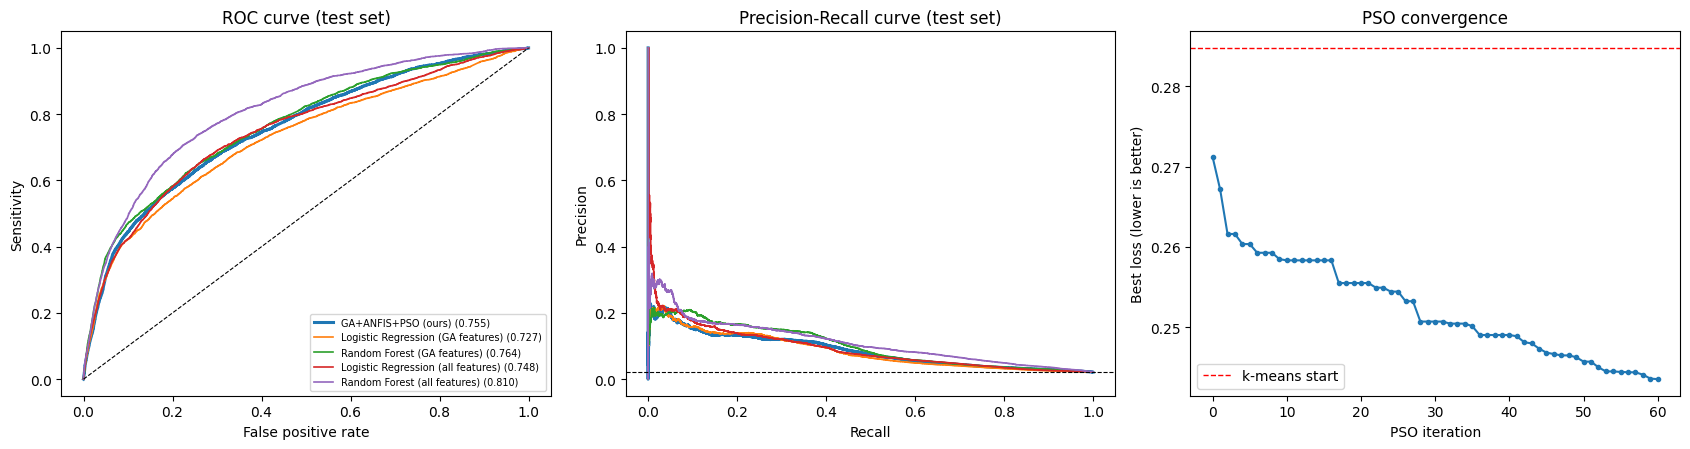

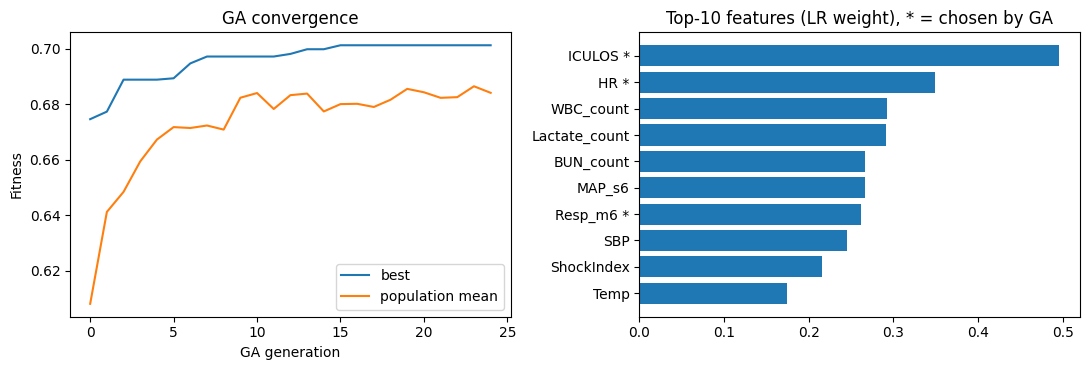

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(17,4.6))
for n,(yy,s) in roc_data.items():
    f,t,_ = roc_curve(yy,s); ax[0].plot(f,t,label='%s (%.3f)' % (n, auc_fast(yy,s)), lw=2.2 if 'ours' in n else 1.2)
    p,r,_ = precision_recall_curve(yy,s); ax[1].plot(r,p,lw=2.2 if 'ours' in n else 1.2)
ax[0].plot([0,1],[0,1],'k--',lw=.8); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('Sensitivity'); ax[0].set_title('ROC curve (test set)'); ax[0].legend(fontsize=7)
ax[1].axhline(y[te_idx].mean(), color='k', ls='--', lw=.8); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision-Recall curve (test set)')
ax[2].plot(range(len(pso_hist)), pso_hist, 'o-', ms=3); ax[2].axhline(init_fit, color='r', ls='--', lw=1, label='k-means start')
ax[2].set_xlabel('PSO iteration'); ax[2].set_ylabel('Best loss (lower is better)'); ax[2].set_title('PSO convergence'); ax[2].legend()
plt.tight_layout(); plt.savefig('figs/roc_pr_pso.png', dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11,3.8))
ax[0].plot(ga_best_hist, label='best'); ax[0].plot(ga_mean_hist, label='population mean'); ax[0].set_xlabel('GA generation'); ax[0].set_ylabel('Fitness'); ax[0].set_title('GA convergence'); ax[0].legend()
imp = np.abs(lr_all.coef_[0]); top = np.argsort(-imp)[:10]
ax[1].barh([FEATS[i]+(' *' if i in sel_cols else '') for i in top][::-1], imp[top][::-1]); ax[1].set_title('Top-10 features (LR weight), * = chosen by GA')
plt.tight_layout(); plt.savefig('figs/ga.png', dpi=200); plt.show()

## 9. Explainability: rules and sample patients (real test patients)

Fuzzy rule centres in REAL units (each rule = one patient profile):


,HR,BUN,ICULOS,Resp_m6,Temp_s6
Rule 1,87.7,3.6,38.8,21.3,0.3
Rule 2,75.3,15.3,1.0,18.9,0.8
Rule 3,101.0,9.4,50.8,15.8,0.2
Rule 4,48.5,1.0,104.1,17.4,0.0
Rule 5,84.4,76.7,34.0,20.2,0.0
Rule 6,87.4,34.6,118.2,21.9,0.2
Rule 7,94.0,25.8,13.0,18.2,0.4
Rule 8,102.0,2.6,12.4,26.2,0.3


Rule 1: IF BUN is LOW (~3.6) AND Resp_m6 is HIGH (~21.3)
Rule 2: IF HR is LOW (~75.3) AND ICULOS is LOW (~1.0) AND Temp_s6 is HIGH (~0.8)
Rule 3: IF HR is HIGH (~101.0) AND BUN is LOW (~9.4) AND ICULOS is HIGH (~50.8) AND Resp_m6 is LOW (~15.8)
Rule 4: IF HR is LOW (~48.5) AND BUN is LOW (~1.0) AND ICULOS is HIGH (~104.1) AND Temp_s6 is LOW (~0.0)
Rule 5: IF BUN is HIGH (~76.7) AND Temp_s6 is LOW (~0.0)
Rule 6: IF BUN is HIGH (~34.6) AND ICULOS is HIGH (~118.2) AND Resp_m6 is HIGH (~21.9)
Rule 7: IF HR is HIGH (~94.0) AND Temp_s6 is HIGH (~0.4)
Rule 8: IF HR is HIGH (~102.0) AND BUN is LOW (~2.6) AND ICULOS is LOW (~12.4) AND Resp_m6 is HIGH (~26.2)

Patient A (developing sepsis) | risk 7.50% | threshold 1.33% | main rule: Rule 6 (100.0%)
   vitals/inputs: {'HR': 87.0, 'BUN': 14.0, 'ICULOS': 117.0, 'Resp_m6': 17.0, 'Temp_s6': 0.0}

Patient B (stable) | risk 0.90% | threshold 1.33% | main rule: Rule 2 (46.6%)
   vitals/inputs: {'HR': 72.0, 'BUN': 17.0, 'ICULOS': 3.0, 'Resp_m6': 16.5, 'T

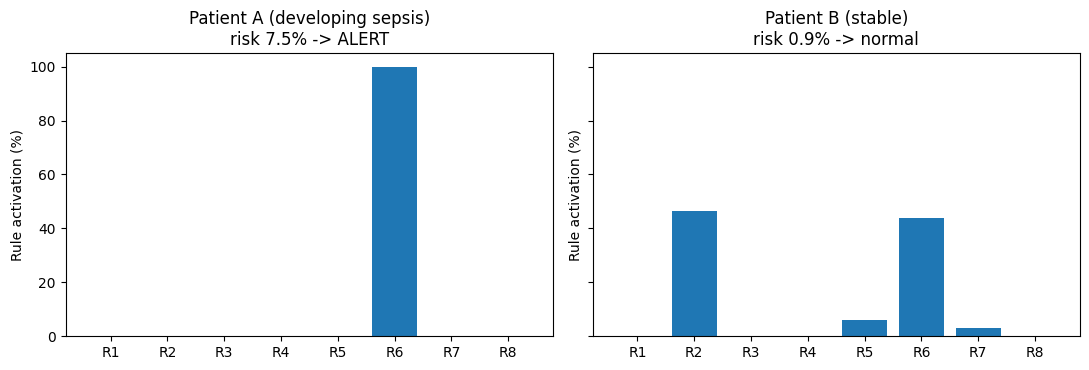

In [23]:
Cb, Sb = decode(gbest)
raw_c = np.clip(Cb * sd.values[sel_cols] + mu.values[sel_cols], F[tr_mask][sel_names].min().values, F[tr_mask][sel_names].max().values)
rules = pd.DataFrame(raw_c, columns=sel_names, index=[f'Rule {i+1}' for i in range(R)]).round(1)
print('Fuzzy rule centres in REAL units (each rule = one patient profile):'); display(rules)
def describe(r):
    parts = []
    for j,n in enumerate(sel_names):
        z = Cb[r,j]
        if abs(z) > 0.5: parts.append('%s is %s (~%.1f)' % (n, 'HIGH' if z>0 else 'LOW', raw_c[r,j]))
    return ' AND '.join(parts) if parts else 'all inputs near normal'
for r in range(R): print('Rule %d: IF %s' % (r+1, describe(r)))

te_df = pd.DataFrame({'row': te_idx, 'pid': pid[te_idx], 'y': y[te_idx], 'p': p_te})
sep = te_df[te_df.y==1].groupby('pid').first().reset_index()
sep_hit = sep[sep.p >= thr_anfis]; A = (sep_hit if len(sep_hit) else sep).sort_values('p', ascending=False).iloc[len(sep_hit)//4 if len(sep_hit)>4 else 0]
stable = te_df[(te_df.y==0)].sample(2000, random_state=SEED, replace=len(te_df[te_df.y==0])<2000); B = stable.sort_values('p').iloc[len(stable)//4]
fig, ax = plt.subplots(1, 2, figsize=(11,3.8), sharey=True)
for a,(lab,rw) in zip(ax, [('Patient A (developing sepsis)',A),('Patient B (stable)',B)]):
    w,_ = phi(Xs[[int(rw.row)]], Cb, Sb); w = w[0]*100
    a.bar([f'R{i+1}' for i in range(R)], w); a.set_title('%s\nrisk %.1f%% -> %s' % (lab, 100*rw.p, 'ALERT' if rw.p>=thr_anfis else 'normal')); a.set_ylabel('Rule activation (%)')
    print('\n%s | risk %.2f%% | threshold %.2f%% | main rule: Rule %d (%.1f%%)' % (lab, 100*rw.p, 100*thr_anfis, w.argmax()+1, w.max()))
    print('   vitals/inputs:', {n: round(float(F.iloc[int(rw.row)][n]),1) for n in sel_names})
plt.tight_layout(); plt.savefig('figs/rules_patients.png', dpi=200); plt.show()

## 10. Summary and download

In [24]:
print('=========== SUMMARY (paste into report) ===========')
print('Patients used: %d (patient-level split 60/20/20) | records: %d' % (df.pid.nunique(), len(df)))
print('Selected features:', sel_names)
print('GA time %.1fs | PSO time %.1fs | per-record prediction %.2f us' % (ga_time, pso_time, per_rec_us))
print('Alert threshold %.2f%% (validation, target sensitivity %.0f%%)' % (100*thr_anfis, 100*TARGET_SENS))
display(tab)
try:
    import shutil; shutil.make_archive('aat_outputs','zip','figs'); shutil.copy('results_table.csv','figs/')
    shutil.make_archive('aat_outputs','zip','figs')
    from google.colab import files; files.download('aat_outputs.zip')
except Exception as e: print('Download skipped:', e)

=========== SUMMARY (paste into report) ===========
Patients used: 20336 (patient-level split 60/20/20) | records: 790215
Selected features: ['HR', 'BUN', 'ICULOS', 'Resp_m6', 'Temp_s6']
GA time 14.6s | PSO time 98.1s | per-record prediction 1.48 us
Alert threshold 1.33% (validation, target sensitivity 80%)


,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1,Accuracy,FalseAlarms_per_TrueAlert,SepsisPatients_alerted,NonSepsisPatients_alerted,TrainTime_s
Model,,,,,,,,,,,
GA+ANFIS+PSO (ours),0.7547,0.0860,83.7,45.8,3.3,0.0630,46.6,29.5738,100.0,98.8,112.6878
Logistic Regression (GA features),0.7270,0.0835,84.3,37.4,2.9,0.0554,38.4,33.9410,92.7,91.6,0.0727
Random Forest (GA features),0.7642,0.0994,85.0,45.6,3.3,0.0637,46.5,29.2192,99.7,98.0,4.8283
Logistic Regression (all features),0.7483,0.0929,82.6,45.3,3.2,0.0616,46.1,30.2656,93.6,87.9,0.2687
Random Forest (all features),0.8100,0.1107,82.5,61.3,4.5,0.0846,61.8,21.4281,96.9,77.4,11.1977


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
# ===================================================================================
#  EXPORT THE TRAINED MODEL  (paste as a NEW LAST CELL of the Colab notebook and run it)
#  Run it in the SAME session, after the notebook has finished (all cells executed).
#  It saves model.json, which the web app loads from  artifacts/model.json
#  Nothing is retrained: it only writes out what the notebook already computed.
# ===================================================================================
import json, datetime
import numpy as np
from sklearn.metrics import roc_curve, precision_recall_curve

EXPECTED_FEATURES = ['HR','O2Sat','Temp','SBP','MAP','DBP','Resp','WBC','Lactate','Creatinine','Platelets','BUN',
    'ShockIndex','Age','ICULOS','WBC_count','Lactate_count','Creatinine_count','Platelets_count','BUN_count',
    'HR_d6','HR_m6','O2Sat_d6','O2Sat_m6','Temp_d6','Temp_m6','SBP_d6','SBP_m6','MAP_d6','MAP_m6','Resp_d6','Resp_m6',
    'HR_s6','Temp_s6','SBP_s6','Resp_s6','MAP_s6']
assert list(FEATS) == EXPECTED_FEATURES, "Feature list differs from the web app's list. Use the v2 notebook."
for _v in ['gbest','th1','platt','mu','sd','sel_cols','sel_names','thr_anfis','results','roc_data','pso_hist','ga_best_hist']:
    assert _v in globals(), f"Variable '{_v}' not found. Run ALL notebook cells first (same session), then this cell."

_f = float
def _curves(yy, s, n=200):
    fpr, tpr, _ = roc_curve(yy, s); i = np.unique(np.linspace(0, len(fpr)-1, min(n, len(fpr))).astype(int))
    p, r, _ = precision_recall_curve(yy, s); j = np.unique(np.linspace(0, len(p)-1, min(n, len(p))).astype(int))
    return ({'fpr': [round(_f(v),5) for v in fpr[i]], 'tpr': [round(_f(v),5) for v in tpr[i]]},
            {'recall': [round(_f(v),5) for v in r[j]], 'precision': [round(_f(v),5) for v in p[j]]})
def _model_row(r):
    return {'model': r['Model'], 'auroc': _f(r['AUROC']), 'auprc': _f(r['AUPRC']), 'sensitivity': _f(r['Sensitivity']),
            'specificity': _f(r['Specificity']), 'precision': _f(r['Precision']), 'f1': _f(r['F1']), 'accuracy': _f(r['Accuracy']),
            'false_alarms_per_true_alert': _f(r['FalseAlarms_per_TrueAlert']),
            'sepsis_patients_alerted': _f(r['SepsisPatients_alerted']), 'non_sepsis_patients_alerted': _f(r['NonSepsisPatients_alerted']),
            'train_time_s': _f(r.get('TrainTime_s', 0.0))}

R_, K_ = N_RULES, len(sel_cols)
C_ = np.asarray(gbest[:R_*K_]).reshape(R_, K_); S_ = np.exp(np.asarray(gbest[R_*K_:])).reshape(R_, K_)
roc_all, pr_all = {}, {}
for name, (yy, ss) in roc_data.items():
    roc_all[name], pr_all[name] = _curves(yy, ss)
trF = F[tr_mask]
medians_ = trF.median()          # imputation values (median of the filled data equals the original median)
models_ = [_model_row(r) for r in results]

artifact = {
    'format_version': 1,
    'name': 'GA + ANFIS + PSO sepsis early-warning model (trained in the Colab notebook)',
    'version': '2.0.0',
    'source': 'colab-notebook-v2',
    'created': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
    'config': {'seed': SEED, 'target_sens': TARGET_SENS, 'k_min': K_MIN, 'k_max': K_MAX, 'n_rules': N_RULES,
               'ga_pop': GA_POP, 'ga_gen': GA_GEN, 'pso_particles': PSO_PARTICLES, 'pso_iters': PSO_ITERS,
               'rf_trees': 200, 'fit_pos': 4000, 'fit_neg': 8000, 'sel_pos': 2500, 'sel_neg': 5000, 'n_patients': N_PATIENTS},
    'dataset': {'patients': int(len(pid_all)), 'records': int(len(df)), 'sepsis_patients': int(pid_all.sum()),
                'sepsis_records': int(y.sum()), 'sepsis_rate': _f(y.mean()), 'train_patients': int(len(tr_p)),
                'validation_patients': int(len(va_p)), 'test_patients': int(len(te_p)),
                'validation_rows': int(len(va_idx)), 'test_rows': int(len(te_idx)), 'test_sepsis_rate': _f(y[te_idx].mean()),
                'fit_rows': int(len(fit_idx)), 'select_rows': int(len(sel_idx))},
    'features': {'all': list(FEATS), 'selected': list(sel_names), 'selected_idx': [int(i) for i in sel_cols]},
    'preprocessing': {'clip': 5.0,
                      'medians': {k: _f(v) for k, v in medians_.items()},
                      'mean': {k: _f(v) for k, v in mu.items()},
                      'std': {k: _f(v) for k, v in sd.items()},
                      'range_min': {n: _f(trF[n].min()) for n in sel_names},
                      'range_max': {n: _f(trF[n].max()) for n in sel_names}},
    'anfis': {'n_rules': int(R_), 'centers': C_.tolist(), 'sigmas': S_.tolist(), 'theta': np.asarray(th1).tolist()},
    'calibration': {'coef': _f(platt.coef_[0][0]), 'intercept': _f(platt.intercept_[0])},
    'alert': {'threshold': _f(thr_anfis), 'target_sensitivity': _f(TARGET_SENS)},
    'metrics': {'anfis': models_[0], 'confusion': {'tn': int(cm[0]), 'fp': int(cm[1]), 'fn': int(cm[2]), 'tp': int(cm[3])},
                'models': models_, 'ga_quick_auc_selected': _f(ga_fitness(best)[1]),
                'ga_quick_auc_all': _f(auc_fast(yb, lr_all.decision_function(Xb))),
                'val_auc_kmeans_only': _f(auc_v0), 'val_auc_after_pso': _f(auc_v1)},
    'curves': {'roc': roc_all, 'pr': pr_all, 'test_prevalence': _f(y[te_idx].mean())},
    'history': {'ga_best': [_f(v) for v in ga_best_hist], 'ga_mean': [_f(v) for v in ga_mean_hist],
                'pso': [_f(v) for v in pso_hist], 'pso_start': _f(init_fit)},
    'timing': {'ga_s': _f(ga_time), 'pso_s': _f(pso_time), 'predict_us_per_record': _f(per_rec_us)},
}
with open('model.json', 'w') as fh:
    json.dump(artifact, fh)
print('Saved model.json')
print('  selected features :', list(sel_names))
print('  test AUROC        : %.4f (the report says 0.7547 for the original run)' % artifact['metrics']['anfis']['auroc'])
print('  alert threshold   : %.4f' % artifact['alert']['threshold'])
try:
    from google.colab import files
    files.download('model.json')
except Exception as e:
    print('Download manually from the Files panel (folder icon on the left):', e)

Saved model.json
  selected features : ['HR', 'BUN', 'ICULOS', 'Resp_m6', 'Temp_s6']
  test AUROC        : 0.7547 (the report says 0.7547 for the original run)
  alert threshold   : 0.0133


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>